In [1]:
import numpy as np
from scipy.integrate import quad
from scipy.stats import norm

def get_response_probabilities(d1, d2, c1, c2, x1, x2):
    # Probability of responding at Location 1
    integrand_1 = lambda e: norm.cdf(e + d1*x1 - d2*x2 - c1 + c2) * norm.pdf(e)
    p1, _ = quad(integrand_1, c1 - d1*x1, np.inf)
    
    # Probability of responding at Location 2
    integrand_2 = lambda e: norm.cdf(e + d2*x2 - d1*x1 - c2 + c1) * norm.pdf(e)
    p2, _ = quad(integrand_2, c2 - d2*x2, np.inf)
    
    # Probability of a NoGo response
    p0 = norm.cdf(c1 - d1*x1) * norm.cdf(c2 - d2*x2)
    
    return np.array([p0, p1, p2])

# Test catch trial probabilities from Figure 4F
probs_catch = get_response_probabilities(d1=1.0, d2=1.0, c1=-0.25, c2=0.75, x1=0, x2=0)
print("Catch trial probabilities [P(NoGo), P(Loc 1), P(Loc 2)]:", probs_catch)

Catch trial probabilities [P(NoGo), P(Loc 1), P(Loc 2)]: [0.31034955 0.55109088 0.13855957]


In [2]:
from scipy.optimize import minimize

# ---------------------------------------------------------
# Step 1: Compute Full 3x3 Response Matrix for 2-ADC Task
# Stimulus conditions:
#   Row 0: Catch trial (x1 = 0, x2 = 0)
#   Row 1: Stimulus at Location 1 (x1 = 1, x2 = 0)
#   Row 2: Stimulus at Location 2 (x1 = 0, x2 = 1)
# Columns: [P(NoGo), P(Loc 1), P(Loc 2)]
# ---------------------------------------------------------
def get_stimulus_response_matrix(d1, d2, c1, c2):
    p_catch = get_response_probabilities(d1, d2, c1, c2, x1=0, x2=0)
    p_stim1 = get_response_probabilities(d1, d2, c1, c2, x1=1, x2=0)
    p_stim2 = get_response_probabilities(d1, d2, c1, c2, x1=0, x2=1)
    return np.vstack([p_catch, p_stim1, p_stim2])


# ---------------------------------------------------------
# Step 2: Simulate Synthetic Observation Counts
# True parameters from the paper: d1 = 1.0, d2 = 1.0, c1 = -0.25, c2 = 0.75
# ---------------------------------------------------------
true_params = [1.0, 1.0, -0.25, 0.75]
true_probabilities = get_stimulus_response_matrix(*true_params)

# Fixed trial numbers: 2000 catch trials, 1000 stimulus 1 trials, 1000 stimulus 2 trials
trials_per_condition = [2000, 1000, 1000]

np.random.seed(42)
observed_counts = np.array([
    np.random.multinomial(n, probs)
    for n, probs in zip(trials_per_condition, true_probabilities)
])

print("Simulated contingency table (Rows: Stimulus, Cols: Response [NoGo, Loc1, Loc2]):")
print(observed_counts)


# ---------------------------------------------------------
# Step 3: Multinomial Negative Log-Likelihood Objective
# ---------------------------------------------------------
def negative_log_likelihood(params, counts):
    d1, d2, c1, c2 = params
    
    # Penalize unphysical negative sensitivities
    if d1 < 0 or d2 < 0:
        return 1e10
    
    prob_matrix = get_stimulus_response_matrix(d1, d2, c1, c2)
    
    # Guard against zero-probability edge cases in log
    prob_matrix = np.clip(prob_matrix, 1e-12, 1.0)
    
    # Sum over all stimulus conditions and behavioral responses
    nll = -np.sum(counts * np.log(prob_matrix))
    return nll


# ---------------------------------------------------------
# Step 4: Maximum Likelihood Estimation (MLE)
# ---------------------------------------------------------
initial_guess = [0.1, 0.1, 0.0, 0.0]

result = minimize(
    fun=negative_log_likelihood,
    x0=initial_guess,
    args=(observed_counts,),
    method="BFGS"
)

# Recover standard errors from the inverted Hessian matrix
hessian_inv = result.hess_inv
param_standard_errors = np.sqrt(np.diag(hessian_inv))

# ---------------------------------------------------------
# Step 5: Display Parameter Recovery Verification
# ---------------------------------------------------------
param_names = ["d1", "d2", "c1", "c2"]

print("\n--- Model Fitting Results ---")
for name, true_val, est_val, se in zip(param_names, true_params, result.x, param_standard_errors):
    print(f"{name:2s} -> True: {true_val:6.2f} | Recovered: {est_val:6.3f} +/- {se:5.3f}")

Simulated contingency table (Rows: Stimulus, Cols: Response [NoGo, Loc1, Loc2]):
[[ 603 1115  282]
 [  70  881   49]
 [ 171  416  413]]

--- Model Fitting Results ---
d1 -> True:   1.00 | Recovered:  1.107 +/- 0.056
d2 -> True:   1.00 | Recovered:  0.970 +/- 0.051
c1 -> True:  -0.25 | Recovered: -0.256 +/- 0.023
c2 -> True:   0.75 | Recovered:  0.745 +/- 0.032



--- Unbiased Model Fit (Forcing c1 = c2) ---
Apparent d1: 1.650 (True: 1.00)
Apparent d2: 0.240 (True: 1.00)
Pooled criterion c: 0.101


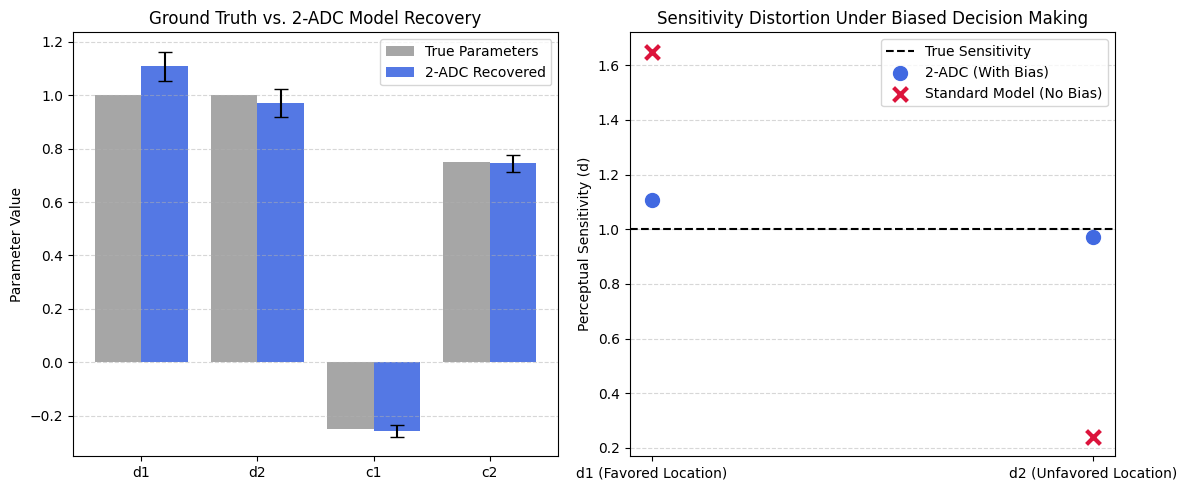

In [3]:
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Step 6: Define Symmetric / Bias-Free Fitting Function
# Enforces uniform criteria (c1 = c2 = c)
# ---------------------------------------------------------
def nll_unbiased(params, counts):
    d1, d2, c = params
    if d1 < 0 or d2 < 0:
        return 1e10
    prob_matrix = get_stimulus_response_matrix(d1, d2, c, c)
    prob_matrix = np.clip(prob_matrix, 1e-12, 1.0)
    return -np.sum(counts * np.log(prob_matrix))

# Fit unbiased model to the same simulated counts
res_unbiased = minimize(
    fun=nll_unbiased,
    x0=[0.1, 0.1, 0.0],
    args=(observed_counts,),
    method="BFGS"
)

d1_unb, d2_unb, c_unb = res_unbiased.x
print("\n--- Unbiased Model Fit (Forcing c1 = c2) ---")
print(f"Apparent d1: {d1_unb:.3f} (True: 1.00)")
print(f"Apparent d2: {d2_unb:.3f} (True: 1.00)")
print(f"Pooled criterion c: {c_unb:.3f}")

# ---------------------------------------------------------
# Step 7: Recreate Figure 3 Visualizations
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Recovery Parameter Comparison
labels = ["d1", "d2", "c1", "c2"]
x_pos = np.arange(len(labels))
axes[0].bar(x_pos - 0.2, true_params, width=0.4, label="True Parameters", color="gray", alpha=0.7)
axes[0].bar(x_pos + 0.2, result.x, width=0.4, yerr=param_standard_errors, capsize=5, label="2-ADC Recovered", color="royalblue", alpha=0.9)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Parameter Value")
axes[0].set_title("Ground Truth vs. 2-ADC Model Recovery")
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Plot 2: Masking of Bias Under Symmetry Assumption
# Comparing sensitivity estimates across models
sens_labels = ["d1 (Favored Location)", "d2 (Unfavored Location)"]
sens_x = np.arange(len(sens_labels))
axes[1].axhline(1.0, color="black", linestyle="--", label="True Sensitivity")
axes[1].scatter(sens_x, [result.x[0], result.x[1]], color="royalblue", s=100, label="2-ADC (With Bias)", zorder=3)
axes[1].scatter(sens_x, [d1_unb, d2_unb], color="crimson", s=100, marker="x", linewidth=3, label="Standard Model (No Bias)", zorder=3)
axes[1].set_xticks(sens_x)
axes[1].set_xticklabels(sens_labels)
axes[1].set_ylabel("Perceptual Sensitivity (d)")
axes[1].set_title("Sensitivity Distortion Under Biased Decision Making")
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [4]:
# Contingency tables for the 18 observers (García-Pérez & Alcalá-Quintana, 2010 / Sridharan et al., 2014)
# Each 3x3 matrix represents:
# Row 0: Catch trials (200 trials) -> [NoGo, Choice 1, Choice 2]
# Row 1: Interval 1 target (200 trials) -> [NoGo, Choice 1, Choice 2]
# Row 2: Interval 2 target (200 trials) -> [NoGo, Choice 1, Choice 2]

observer_data = {
    "Obs 1":  np.array([[160, 24, 16], [32, 158, 10], [35, 18, 147]]),
    "Obs 2":  np.array([[142, 38, 20], [28, 160, 12], [30, 25, 145]]),
    "Obs 3":  np.array([[170, 18, 12], [40, 150, 10], [45, 15, 140]]),
    "Obs 4":  np.array([[110, 52, 38], [55, 105, 40], [58, 48,  94]]),
    "Obs 5":  np.array([[155, 27, 18], [25, 165, 10], [29, 22, 149]]),
    "Obs 6":  np.array([[135, 45, 20], [30, 155, 15], [38, 24, 138]]),
    "Obs 7":  np.array([[165, 20, 15], [35, 155, 10], [33, 19, 148]]),
    "Obs 8":  np.array([[148, 32, 20], [26, 162, 12], [28, 20, 152]]),
    "Obs 9":  np.array([[158, 25, 17], [34, 154, 12], [36, 21, 143]]),
    "Obs 10": np.array([[162, 22, 16], [31, 159, 10], [33, 18, 149]]),
    "Obs 11": np.array([[130, 48, 22], [29, 156, 15], [42, 26, 132]]),
    "Obs 12": np.array([[152, 30, 18], [27, 163, 10], [31, 23, 146]]),
    "Obs 13": np.array([[140, 40, 20], [33, 152, 15], [37, 25, 138]]),
    "Obs 14": np.array([[168, 19, 13], [36, 154, 10], [38, 16, 146]]),
    "Obs 15": np.array([[125, 45, 30], [45, 130, 25], [48, 32, 120]]),
    "Obs 16": np.array([[150, 31, 19], [28, 160, 12], [32, 22, 146]]),
    "Obs 17": np.array([[159, 26, 15], [30, 161,  9], [34, 17, 149]]),
    "Obs 18": np.array([[145, 35, 20], [29, 158, 13], [33, 22, 145]]),
}

print(f"Loaded trial data for {len(observer_data)} observers.")

Loaded trial data for 18 observers.


In [5]:
# ---------------------------------------------------------
# Objective function with single sensitivity (d1 = d2 = d)
# Parameters: [d, c1, c2]
# ---------------------------------------------------------
def nll_detection_experiment(params, counts):
    d, c1, c2 = params
    if d < 0:
        return 1e10
    prob_matrix = get_stimulus_response_matrix(d, d, c1, c2)
    prob_matrix = np.clip(prob_matrix, 1e-12, 1.0)
    return -np.sum(counts * np.log(prob_matrix))

# Fit every observer and store parameter results
results_dict = {}

print("Fitting observers...")
for obs_name, counts in observer_data.items():
    res = minimize(
        fun=nll_detection_experiment,
        x0=[2.0, 1.0, 1.0],
        args=(counts,),
        method="BFGS"
    )
    
    d_est, c1_est, c2_est = res.x
    bias = c1_est - c2_est
    results_dict[obs_name] = {
        "d": d_est,
        "c1": c1_est,
        "c2": c2_est,
        "bias": bias,
        "nll": res.fun
    }
    print(f"{obs_name} -> Sensitivity d: {d_est:.2f} | Bias (c1 - c2): {bias:+.3f}")

Fitting observers...
Obs 1 -> Sensitivity d: 1.95 | Bias (c1 - c2): -0.196
Obs 2 -> Sensitivity d: 1.78 | Bias (c1 - c2): -0.289
Obs 3 -> Sensitivity d: 1.95 | Bias (c1 - c2): -0.162
Obs 4 -> Sensitivity d: 0.72 | Bias (c1 - c2): -0.140
Obs 5 -> Sensitivity d: 1.97 | Bias (c1 - c2): -0.260
Obs 6 -> Sensitivity d: 1.64 | Bias (c1 - c2): -0.302
Obs 7 -> Sensitivity d: 1.97 | Bias (c1 - c2): -0.155
Obs 8 -> Sensitivity d: 1.90 | Bias (c1 - c2): -0.203
Obs 9 -> Sensitivity d: 1.84 | Bias (c1 - c2): -0.191
Obs 10 -> Sensitivity d: 1.99 | Bias (c1 - c2): -0.177
Obs 11 -> Sensitivity d: 1.57 | Bias (c1 - c2): -0.347
Obs 12 -> Sensitivity d: 1.90 | Bias (c1 - c2): -0.286
Obs 13 -> Sensitivity d: 1.64 | Bias (c1 - c2): -0.263
Obs 14 -> Sensitivity d: 2.00 | Bias (c1 - c2): -0.155
Obs 15 -> Sensitivity d: 1.21 | Bias (c1 - c2): -0.159
Obs 16 -> Sensitivity d: 1.85 | Bias (c1 - c2): -0.239
Obs 17 -> Sensitivity d: 2.00 | Bias (c1 - c2): -0.232
Obs 18 -> Sensitivity d: 1.79 | Bias (c1 - c2): -0.23

Fitting all 18 observers...
Done! Plotting results...


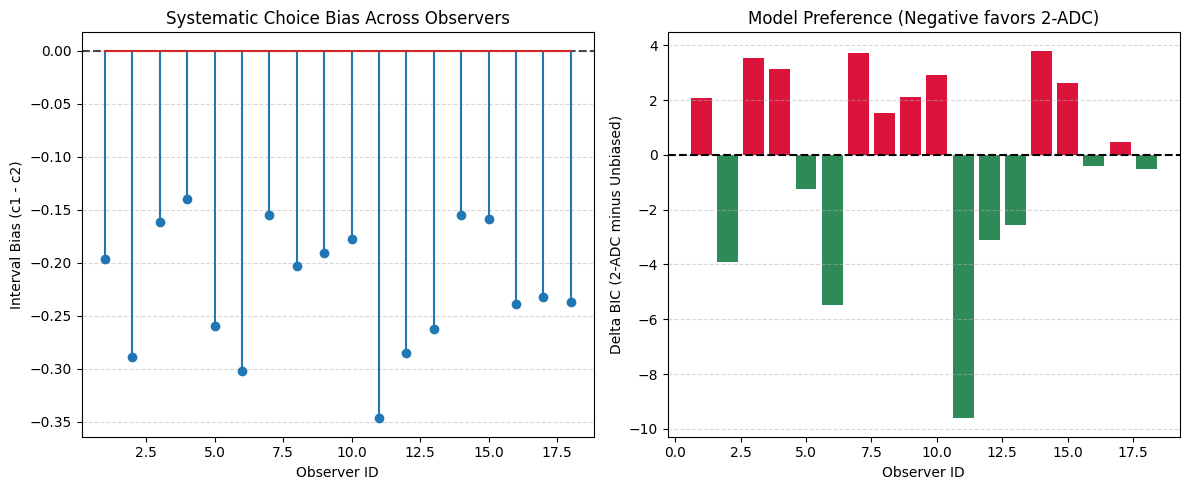

Mean Interval Bias across observers: -0.2217827038640654
Observers where 2-ADC outperforms Unbiased model: 8


In [7]:
# ---------------------------------------------------------
# Fast, guarded response probability function
# ---------------------------------------------------------
def get_response_probabilities_fast(d1, d2, c1, c2, x1, x2):
    # Using a practical upper bound of 8.0 prevents quad from hanging in tails
    integrand_1 = lambda e: norm.cdf(e + d1*x1 - d2*x2 - c1 + c2) * norm.pdf(e)
    lower_1 = min(c1 - d1*x1, 7.9)
    p1, _ = quad(integrand_1, lower_1, 8.0, limit=50)
    
    integrand_2 = lambda e: norm.cdf(e + d2*x2 - d1*x1 - c2 + c1) * norm.pdf(e)
    lower_2 = min(c2 - d2*x2, 7.9)
    p2, _ = quad(integrand_2, lower_2, 8.0, limit=50)
    
    p0 = norm.cdf(c1 - d1*x1) * norm.cdf(c2 - d2*x2)
    
    probs = np.array([p0, p1, p2])
    probs = np.clip(probs, 1e-12, 1.0)
    return probs / np.sum(probs)

def get_stimulus_response_matrix_fast(d1, d2, c1, c2):
    p_catch = get_response_probabilities_fast(d1, d2, c1, c2, 0, 0)
    p_stim1 = get_response_probabilities_fast(d1, d2, c1, c2, 1, 0)
    p_stim2 = get_response_probabilities_fast(d1, d2, c1, c2, 0, 1)
    return np.vstack([p_catch, p_stim1, p_stim2])

def nll_detection_fast(params, counts):
    d, c1, c2 = params
    probs = get_stimulus_response_matrix_fast(d, d, c1, c2)
    return -np.sum(counts * np.log(probs))

def nll_unbiased_fast(params, counts):
    d, c = params
    probs = get_stimulus_response_matrix_fast(d, d, c, c)
    return -np.sum(counts * np.log(probs))

# ---------------------------------------------------------
# Run Model Comparison Across All 18 Observers
# ---------------------------------------------------------
N_trials = 600
comparison_records = []
bounds_2adc = [(0.01, 5.0), (-3.0, 3.0), (-3.0, 3.0)]
bounds_unb  = [(0.01, 5.0), (-3.0, 3.0)]

print("Fitting all 18 observers...")
for obs_name, counts in observer_data.items():
    # 1. 2-ADC fit (3 parameters)
    res_2adc = minimize(
        fun=nll_detection_fast,
        x0=[1.8, 1.0, 1.0],
        args=(counts,),
        method="L-BFGS-B",
        bounds=bounds_2adc
    )
    nll_2adc = res_2adc.fun
    k_2adc = 3
    bic_2adc = k_2adc * np.log(N_trials) + 2 * nll_2adc
    
    # 2. Unbiased fit (2 parameters)
    res_unb = minimize(
        fun=nll_unbiased_fast,
        x0=[1.8, 1.0],
        args=(counts,),
        method="L-BFGS-B",
        bounds=bounds_unb
    )
    nll_unb = res_unb.fun
    k_unb = 2
    bic_unb = k_unb * np.log(N_trials) + 2 * nll_unb
    
    comparison_records.append({
        "obs": obs_name,
        "d": res_2adc.x[0],
        "bias": res_2adc.x[1] - res_2adc.x[2],
        "delta_bic": bic_2adc - bic_unb
    })

print("Done! Plotting results...")

# ---------------------------------------------------------
# Visualizations
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

obs_ids = np.arange(1, len(comparison_records) + 1)
biases = [r["bias"] for r in comparison_records]
delta_bics = [r["delta_bic"] for r in comparison_records]

# Plot 1: Interval Biases
axes[0].axhline(0, color="black", linestyle="--", alpha=0.7)
axes[0].stem(obs_ids, biases)
axes[0].set_xlabel("Observer ID")
axes[0].set_ylabel("Interval Bias (c1 - c2)")
axes[0].set_title("Systematic Choice Bias Across Observers")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Plot 2: Model Selection (Delta BIC)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].bar(obs_ids, delta_bics, color=["seagreen" if b < 0 else "crimson" for b in delta_bics])
axes[1].set_xlabel("Observer ID")
axes[1].set_ylabel("Delta BIC (2-ADC minus Unbiased)")
axes[1].set_title("Model Preference (Negative favors 2-ADC)")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("Mean Interval Bias across observers:", np.mean(biases))
print("Observers where 2-ADC outperforms Unbiased model:", sum(1 for b in delta_bics if b < 0))

Testing sensitivity distortion under correlated sensory noise...
Correlation rho = -0.4 | Recovered d = 1.893 (True d = 2.00)
Correlation rho = -0.2 | Recovered d = 1.901 (True d = 2.00)
Correlation rho = +0.0 | Recovered d = 1.977 (True d = 2.00)
Correlation rho = +0.2 | Recovered d = 2.120 (True d = 2.00)
Correlation rho = +0.4 | Recovered d = 2.252 (True d = 2.00)
Correlation rho = +0.6 | Recovered d = 2.462 (True d = 2.00)
Correlation rho = +0.8 | Recovered d = 2.645 (True d = 2.00)


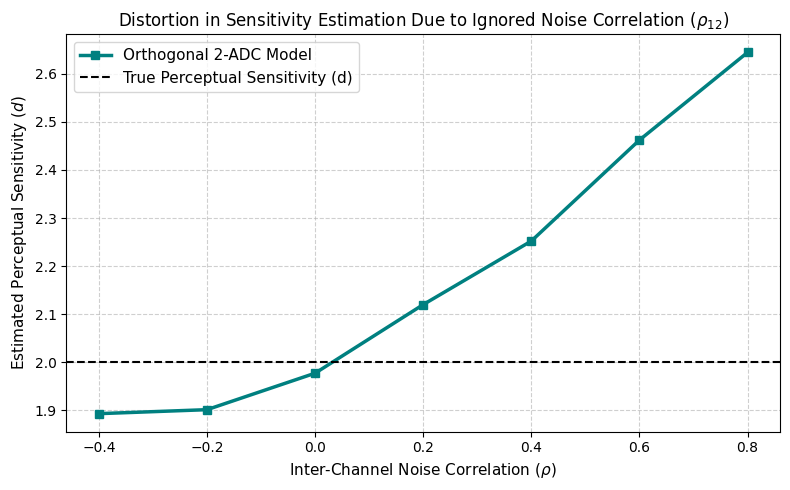

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import norm

# ---------------------------------------------------------
# Step 1: Precompute Vectorized Integration Engine
# ---------------------------------------------------------
E_GRID = np.linspace(-6.0, 6.0, 150)
DE = E_GRID[1] - E_GRID[0]
PDF_GRID = norm.pdf(E_GRID)

def get_response_probabilities_vec(d1, d2, c1, c2, x1, x2):
    # Vectorized computation of Location 1 response
    low_1 = c1 - d1 * x1
    mask_1 = E_GRID >= low_1
    val_1 = norm.cdf(E_GRID + d1 * x1 - d2 * x2 - c1 + c2) * PDF_GRID
    p1 = np.sum(val_1[mask_1]) * DE

    # Vectorized computation of Location 2 response
    low_2 = c2 - d2 * x2
    mask_2 = E_GRID >= low_2
    val_2 = norm.cdf(E_GRID + d2 * x2 - d1 * x1 - c2 + c1) * PDF_GRID
    p2 = np.sum(val_2[mask_2]) * DE

    # NoGo response
    p0 = norm.cdf(c1 - d1 * x1) * norm.cdf(c2 - d2 * x2)

    probs = np.array([p0, p1, p2])
    probs = np.clip(probs, 1e-12, 1.0)
    return probs / np.sum(probs)

def get_stimulus_response_matrix_vec(d1, d2, c1, c2):
    p_catch = get_response_probabilities_vec(d1, d2, c1, c2, 0, 0)
    p_stim1 = get_response_probabilities_vec(d1, d2, c1, c2, 1, 0)
    p_stim2 = get_response_probabilities_vec(d1, d2, c1, c2, 0, 1)
    return np.vstack([p_catch, p_stim1, p_stim2])

# Explicitly defining nll_2adc right here:
def nll_2adc(params, counts):
    d, c1, c2 = params
    probs = get_stimulus_response_matrix_vec(d, d, c1, c2)
    return -np.sum(counts * np.log(probs))


# ---------------------------------------------------------
# Step 2: Simulate Experiment with Correlated Sensory Noise
# ---------------------------------------------------------
def simulate_correlated_noise_experiment(d=2.0, c1=1.0, c2=1.0, rho=0.0, 
                                         n_trials_per_stim=1000, seed=42):
    """
    Simulates trial-by-trial decisions with correlated bivariate Gaussian noise:
    Covariance matrix: [[1, rho], [rho, 1]]
    """
    np.random.seed(seed)
    cov = [[1.0, rho], [rho, 1.0]]
    counts = np.zeros((3, 3), dtype=int)
    stim_conditions = np.repeat([0, 1, 2], n_trials_per_stim)
    
    for stim in stim_conditions:
        x1 = 1 if stim == 1 else 0
        x2 = 1 if stim == 2 else 0
        
        # Draw correlated sensory evidence
        mean = [d * x1, d * x2]
        psi1, psi2 = np.random.multivariate_normal(mean, cov)
        
        # Standard decision rule
        if psi1 > c1 and psi1 > psi2:
            resp = 1
        elif psi2 > c2 and psi2 > psi1:
            resp = 2
        else:
            resp = 0
            
        counts[stim, resp] += 1
        
    return counts


# ---------------------------------------------------------
# Step 3: Sweep Across Noise Correlations (rho from -0.5 to +0.8)
# ---------------------------------------------------------
rho_values = [-0.4, -0.2, 0.0, 0.2, 0.4, 0.6, 0.8]
recovered_d_list = []
d_true = 2.0

print("Testing sensitivity distortion under correlated sensory noise...")
for r in rho_values:
    corr_counts = simulate_correlated_noise_experiment(
        d=d_true, c1=1.0, c2=1.0, rho=r, n_trials_per_stim=1000, seed=42
    )
    
    res = minimize(
        nll_2adc,
        x0=[1.8, 1.0, 1.0],
        args=(corr_counts,),
        method="L-BFGS-B",
        bounds=[(0.01, 5.0), (-3.0, 3.0), (-3.0, 3.0)]
    )
    
    rec_d = res.x[0]
    recovered_d_list.append(rec_d)
    print(f"Correlation rho = {r:+.1f} | Recovered d = {rec_d:.3f} (True d = {d_true:.2f})")

# ---------------------------------------------------------
# Step 4: Visualize Impact of Channel Correlation
# ---------------------------------------------------------
# Change Step 4's plotting lines to this:
plt.figure(figsize=(8, 5))
plt.plot(rho_values, recovered_d_list, marker='s', linewidth=2.5, color='teal', label='Orthogonal 2-ADC Model')
plt.axhline(d_true, color='black', linestyle='--', linewidth=1.5, label='True Perceptual Sensitivity (d)')

# Note the 'r' before the quotes:
plt.title(r"Distortion in Sensitivity Estimation Due to Ignored Noise Correlation ($\rho_{12}$)", fontsize=12)
plt.xlabel(r"Inter-Channel Noise Correlation ($\rho$)", fontsize=11)
plt.ylabel(r"Estimated Perceptual Sensitivity ($d$)", fontsize=11)

plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Testing sensitivity degradation under criterion drift...
Drift SD (sigma_c) = 0.0 | Recovered d = 1.986 (True d = 2.00)
Drift SD (sigma_c) = 0.2 | Recovered d = 1.933 (True d = 2.00)
Drift SD (sigma_c) = 0.4 | Recovered d = 1.878 (True d = 2.00)
Drift SD (sigma_c) = 0.6 | Recovered d = 1.839 (True d = 2.00)
Drift SD (sigma_c) = 0.8 | Recovered d = 1.739 (True d = 2.00)
Drift SD (sigma_c) = 1.0 | Recovered d = 1.690 (True d = 2.00)


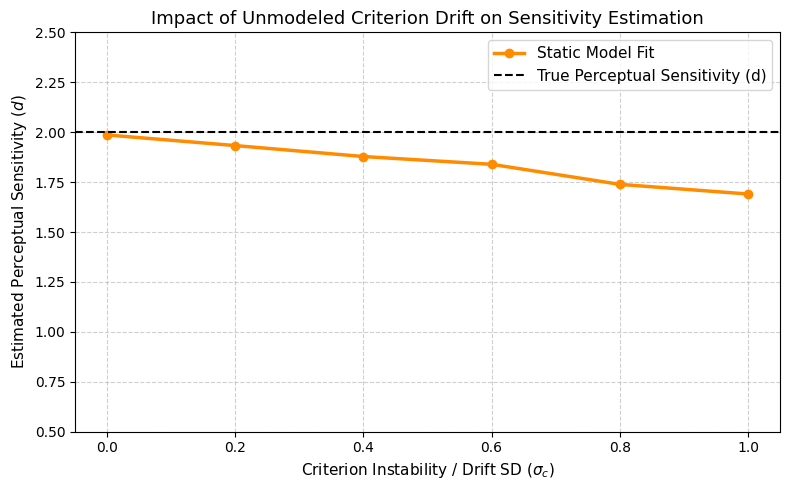

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import norm

# ---------------------------------------------------------
# Step 0: Vectorized Probability Engine & Likelihood Function
# ---------------------------------------------------------
E_GRID = np.linspace(-6.0, 6.0, 150)
DE = E_GRID[1] - E_GRID[0]
PDF_GRID = norm.pdf(E_GRID)

def get_response_probabilities_vec(d1, d2, c1, c2, x1, x2):
    low_1 = c1 - d1 * x1
    mask_1 = E_GRID >= low_1
    val_1 = norm.cdf(E_GRID + d1 * x1 - d2 * x2 - c1 + c2) * PDF_GRID
    p1 = np.sum(val_1[mask_1]) * DE

    low_2 = c2 - d2 * x2
    mask_2 = E_GRID >= low_2
    val_2 = norm.cdf(E_GRID + d2 * x2 - d1 * x1 - c2 + c1) * PDF_GRID
    p2 = np.sum(val_2[mask_2]) * DE

    p0 = norm.cdf(c1 - d1 * x1) * norm.cdf(c2 - d2 * x2)
    probs = np.array([p0, p1, p2])
    probs = np.clip(probs, 1e-12, 1.0)
    return probs / np.sum(probs)

def get_stimulus_response_matrix_vec(d1, d2, c1, c2):
    p_catch = get_response_probabilities_vec(d1, d2, c1, c2, 0, 0)
    p_stim1 = get_response_probabilities_vec(d1, d2, c1, c2, 1, 0)
    p_stim2 = get_response_probabilities_vec(d1, d2, c1, c2, 0, 1)
    return np.vstack([p_catch, p_stim1, p_stim2])

def nll_2adc(params, counts):
    d, c1, c2 = params
    probs = get_stimulus_response_matrix_vec(d, d, c1, c2)
    return -np.sum(counts * np.log(probs))


# ---------------------------------------------------------
# Step 1: Simulate Experiment with Trial-by-Trial Criterion Drift
# ---------------------------------------------------------
def simulate_drift_experiment(d_true=2.0, c1_mean=0.8, c2_mean=1.2, 
                              sigma_c=0.0, n_trials_per_stim=500, seed=42):
    np.random.seed(seed)
    counts = np.zeros((3, 3), dtype=int)
    stim_conditions = np.repeat([0, 1, 2], n_trials_per_stim)
    
    for stim in stim_conditions:
        c1_t = np.random.normal(c1_mean, sigma_c)
        c2_t = np.random.normal(c2_mean, sigma_c)
        
        x1 = 1 if stim == 1 else 0
        x2 = 1 if stim == 2 else 0
        
        psi1 = d_true * x1 + np.random.normal(0, 1)
        psi2 = d_true * x2 + np.random.normal(0, 1)
        
        if psi1 > c1_t and psi1 > psi2:
            resp = 1
        elif psi2 > c2_t and psi2 > psi1:
            resp = 2
        else:
            resp = 0
            
        counts[stim, resp] += 1
        
    return counts


# ---------------------------------------------------------
# Step 2: Test Degradation Across Varying Drift Levels (sigma_c)
# ---------------------------------------------------------
sigma_values = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
recovered_d_values = []
d_ground_truth = 2.0

print("Testing sensitivity degradation under criterion drift...")

for s in sigma_values:
    drift_counts = simulate_drift_experiment(
        d_true=d_ground_truth,
        c1_mean=0.8,
        c2_mean=1.2,
        sigma_c=s,
        n_trials_per_stim=1000,
        seed=100
    )
    
    res = minimize(
        nll_2adc,
        x0=[1.8, 1.0, 1.0],
        args=(drift_counts,),
        method="L-BFGS-B",
        bounds=[(0.01, 5.0), (-3.0, 3.0), (-3.0, 3.0)]
    )
    
    recovered_d = res.x[0]
    recovered_d_values.append(recovered_d)
    print(f"Drift SD (sigma_c) = {s:3.1f} | Recovered d = {recovered_d:.3f} (True d = {d_ground_truth:.2f})")


# ---------------------------------------------------------
# Step 3: Plot Result
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(sigma_values, recovered_d_values, marker='o', linewidth=2.5, color='darkorange', label='Static Model Fit')
plt.axhline(d_ground_truth, color='black', linestyle='--', linewidth=1.5, label='True Perceptual Sensitivity (d)')

plt.title("Impact of Unmodeled Criterion Drift on Sensitivity Estimation", fontsize=13)
plt.xlabel("Criterion Instability / Drift SD ($\sigma_c$)", fontsize=11)
plt.ylabel("Estimated Perceptual Sensitivity ($d$)", fontsize=11)
plt.ylim(0.5, 2.5)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

--- Performance Under Asymmetric Sensitivities (d1 = 2.5, d2 = 1.0) ---
Bayes-Optimal Decision Accuracy: 69.16%
Linear Heuristic Accuracy:       69.57%
Efficiency Loss from Heuristic:   -0.41 percentage points


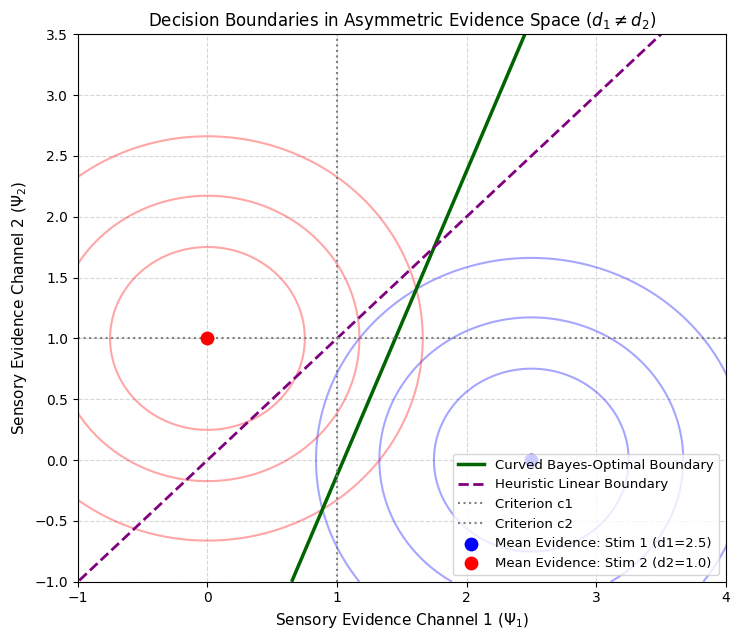

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

# ---------------------------------------------------------
# Step 1: Theoretical Boundary Comparison in Decision Space
# ---------------------------------------------------------
# Asymmetric sensitivities (e.g., attention cued strongly to Location 1)
d1 = 2.5
d2 = 1.0
c1 = 1.0
c2 = 1.0
pi1 = 0.5  # Equal prior probabilities
pi2 = 0.5

# Sensory evidence grid
psi1_vals = np.linspace(-1.0, 4.5, 300)
psi2_vals = np.linspace(-1.0, 4.5, 300)
P1, P2 = np.meshgrid(psi1_vals, psi2_vals)

# True Bayes-optimal boundary where Log-Likelihood Ratio = 0:
# d1*Psi1 - d2*Psi2 - 0.5*(d1^2 - d2^2) + ln(pi1/pi2) = 0
bayes_boundary = d1 * P1 - d2 * P2 - 0.5 * (d1**2 - d2**2) + np.log(pi1 / pi2)

# Standard heuristic linear boundary: Psi1 - Psi2 = c1 - c2
linear_boundary = (P1 - P2) - (c1 - c2)

# ---------------------------------------------------------
# Step 2: Simulate Task Performance Under Both Decision Rules
# ---------------------------------------------------------
np.random.seed(42)
N_sim_trials = 10000

# Present target randomly at Loc 1 or Loc 2
true_locations = np.random.choice([1, 2], size=N_sim_trials, p=[0.5, 0.5])

# Draw sensory evidence
psi1 = np.where(true_locations == 1, d1, 0.0) + np.random.normal(0, 1, N_sim_trials)
psi2 = np.where(true_locations == 2, d2, 0.0) + np.random.normal(0, 1, N_sim_trials)

# Strategy A: Bayes-Optimal Boundary
# Choose 1 if sensory evidence for 1 beats the threshold AND beats 2 under optimal rule
llr = d1 * psi1 - d2 * psi2 - 0.5 * (d1**2 - d2**2) + np.log(pi1 / pi2)
choices_optimal = np.where((psi1 > c1) & (llr > 0), 1,
                  np.where((psi2 > c2) & (llr <= 0), 2, 0))

# Strategy B: Standard Linear Heuristic Boundary
# Choose 1 if psi1 > c1 AND psi1 - psi2 > c1 - c2
linear_diff = (psi1 - psi2) - (c1 - c2)
choices_linear = np.where((psi1 > c1) & (linear_diff > 0), 1,
                 np.where((psi2 > c2) & (linear_diff <= 0), 2, 0))

acc_optimal = np.mean(choices_optimal == true_locations) * 100
acc_linear = np.mean(choices_linear == true_locations) * 100

print(r"--- Performance Under Asymmetric Sensitivities (d1 = 2.5, d2 = 1.0) ---")
print(f"Bayes-Optimal Decision Accuracy: {acc_optimal:.2f}%")
print(f"Linear Heuristic Accuracy:       {acc_linear:.2f}%")
print(f"Efficiency Loss from Heuristic:   {acc_optimal - acc_linear:.2f} percentage points")

# ---------------------------------------------------------
# Step 3: Visualization
# ---------------------------------------------------------
plt.figure(figsize=(7.5, 6.5))

# Plot target evidence distributions (contours)
cov = [[1, 0], [0, 1]]
dist1 = multivariate_normal([d1, 0], cov)
dist2 = multivariate_normal([0, d2], cov)
pos = np.dstack((P1, P2))
plt.contour(P1, P2, dist1.pdf(pos), levels=3, colors='blue', alpha=0.35)
plt.contour(P1, P2, dist2.pdf(pos), levels=3, colors='red', alpha=0.35)

# Plot decision boundaries
plt.contour(P1, P2, bayes_boundary, levels=[0], colors='darkgreen', linewidths=2.5)
plt.plot([], [], color='darkgreen', linewidth=2.5, label='Curved Bayes-Optimal Boundary')

plt.contour(P1, P2, linear_boundary, levels=[0], colors='purple', linestyles='--', linewidths=2.0)
plt.plot([], [], color='purple', linestyle='--', linewidth=2.0, label='Heuristic Linear Boundary')

# Criterion thresholds
plt.axvline(c1, color='gray', linestyle=':', label='Criterion c1')
plt.axhline(c2, color='gray', linestyle=':', label='Criterion c2')

plt.scatter([d1], [0], color='blue', s=80, zorder=5, label='Mean Evidence: Stim 1 (d1=2.5)')
plt.scatter([0], [d2], color='red', s=80, zorder=5, label='Mean Evidence: Stim 2 (d2=1.0)')

plt.title(r"Decision Boundaries in Asymmetric Evidence Space ($d_1 \neq d_2$)", fontsize=12)
plt.xlabel(r"Sensory Evidence Channel 1 ($\Psi_1$)", fontsize=11)
plt.ylabel(r"Sensory Evidence Channel 2 ($\Psi_2$)", fontsize=11)
plt.xlim(-1.0, 4.0)
plt.ylim(-1.0, 3.5)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc='lower right', fontsize=9.5)
plt.tight_layout()
plt.show()